# 09 Transformer编码器、解码器与完整模型搭建

本篇对应网盘资料 `03-视频/day09`，已核对当天 **18个视频文件名**，并在线阅读《08-Tranformer架构和实现.pdf》第51—95页（保留原文件名拼写）。课件编号与学习天数不完全一致：day09仍讲Transformer，不是《09-迁移学习-上.pdf》。视频未逐节转录，课程原代码未读取；本篇按课件接口独立实现，并实际执行示例。

08实现了词嵌入、位置编码、多头注意力和FFN。本篇把这些组件接成 **LayerNorm → 残差子层 → 编码器/解码器层 → N层堆叠 → 词表输出 → 完整Transformer**。重点是弄清每个模块接收什么、输出什么，以及mask如何一路传递。

延续全Markdown Notebook格式。Python代码需**按出现顺序复制到同一个Python会话**执行，本篇会重列用到的基础组件，因此不需要导入08的Notebook。小模型使用CPU和人工整数序列；复制任务仅用于检验训练与生成流程，不代表真实翻译效果。所有图片嵌入Notebook attachments，无需图片目录。

## 1. 本篇路线与张量约定

| 模块 | 输入 | 输出 | 核心问题 |
| --- | --- | --- | --- |
| Embedding + PE | token ID `(B,L)` | `(B,L,D)` | 表示词义与顺序 |
| LayerNorm | `(B,L,D)` | 同形状 | 对每个token的D个特征规范化 |
| EncoderLayer | 源特征、源mask | `(B,S,D)` | self-attention + FFN |
| Encoder | N个EncoderLayer | memory `(B,S,D)` | 多次提取源序列特征 |
| DecoderLayer | 目标特征、memory、两类mask | `(B,T,D)` | causal self-attention + cross-attention + FFN |
| Decoder | N个DecoderLayer | `(B,T,D)` | 对目标前缀进行条件建模 |
| Generator | `(B,T,D)` | `(B,T,V_tgt)` | 映射到目标词表 |

`B`为batch，`S/T`为源/目标输入长度，`D`为d_model，`H`为头数，`N`为层数。**N层不是H个头**：N控制网络深度，H控制每层注意力的子空间划分。所有层保留D，才能进行残差相加。

课程常用 `N=6,D=512,H=8,d_ff=2048`。本篇实际模型取 `B=3,S=5,T=6,N=2,D=32,H=4,d_ff=64`，刻意让B≠H、S≠T，避免等长样例掩盖广播错误。编码器保留完整源长度，memory不是压缩成单个向量的RNN最终隐状态。

## 2. 运行设置

复制运行所需依赖：`pip install torch numpy matplotlib`。固定种子有助于复现实验；不同平台与版本的小数末位可能不同。此处限制CPU线程只为小示例的运行效率，不是生产训练建议。

```python
import math, copy, platform
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(2026)
np.random.seed(2026)
torch.set_num_threads(1)
torch.set_printoptions(precision=4, sci_mode=False)
plt.rcParams['font.family'] = 'Microsoft YaHei'
plt.rcParams['axes.unicode_minus'] = False
PAD, BOS, EOS = 0, 1, 2
B, D, H, N = 3, 32, 4, 2
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__, '| NumPy:', np.__version__)
print('CPU | N,D,H,d_ff:', N, D, H, 64)
```

本段实测输出：

```text
Python: 3.12.13
PyTorch: 2.14.1+cpu | NumPy: 2.5.4
CPU | N,D,H,d_ff: 2 32 4 64
```

## 3. LayerNorm：沿特征轴计算当前输入的统计量

对一个token的向量 `x∈R^D`：

$$\mu=\frac{1}{D}\sum_{i=1}^{D}x_i,\qquad \sigma^2=\frac{1}{D}\sum_{i=1}^{D}(x_i-\mu)^2$$
$$\operatorname{LN}(x)_i=\gamma_i\frac{x_i-\mu}{\sqrt{\sigma^2+\epsilon}}+\beta_i$$

`mean/var(...,dim=-1,keepdim=True)`把 `(B,L,D)` 变成 `(B,L,1)`，再广播回D维。每个token独立计算均值与方差，不与另一个句子、另一个位置混合。γ和β是长度D的**可学习参数**，初始化为1和0，不是训练数据的均值与方差。

课件第52页使用 `x.std(-1)` 和 `(std+eps)`。当前PyTorch默认std采用样本修正；官方LayerNorm用总体方差（correction=0），并把eps加在方差内。本篇统一官方定义，以便准确对照。γ/β学成非恒定值后，LN输出不必继续保持均值0、方差1；eps也会使标准化方差略小于1。

```python
class LayerNorm(nn.Module):
    def __init__(self, features, eps=1e-6):
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(features))
        self.beta = nn.Parameter(torch.zeros(features))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, correction=0, keepdim=True)
        return self.gamma * (x - mean) * torch.rsqrt(var + self.eps) + self.beta

ln = LayerNorm(4)
official_ln = nn.LayerNorm(4, eps=1e-6)
x_ln = torch.tensor([[[1., 2., 3., 4.], [8., 8., 8., 8.]],
                     [[10., 20., 30., 40.], [3., 5., 7., 9.]]])
with torch.no_grad():
    ln.gamma.copy_(torch.tensor([1.2, 0.8, 1.1, 0.9]))
    ln.beta.copy_(torch.tensor([0.1, 0.2, -0.1, 0.3]))
    official_ln.weight.copy_(ln.gamma)
    official_ln.bias.copy_(ln.beta)
    custom_y, official_y = ln(x_ln), official_ln(x_ln)
torch.testing.assert_close(custom_y, official_y, atol=1e-6, rtol=1e-6)
assert torch.isfinite(custom_y).all()
torch.testing.assert_close(custom_y[0, 1], ln.beta)
ln_error = (custom_y - official_y).abs().max().item()
print('LayerNorm官方对照最大误差:', ln_error)
print('常量向量输出为beta、无NaN：通过')
```

本段实测输出：

```text
LayerNorm官方对照最大误差: 1.1920928955078125e-07
常量向量输出为beta、无NaN：通过
```

常量向量的方差为0，eps保证分母非0，输出等于β。仅检查“输出shape没变”无法验证统计维度与公式是否正确。

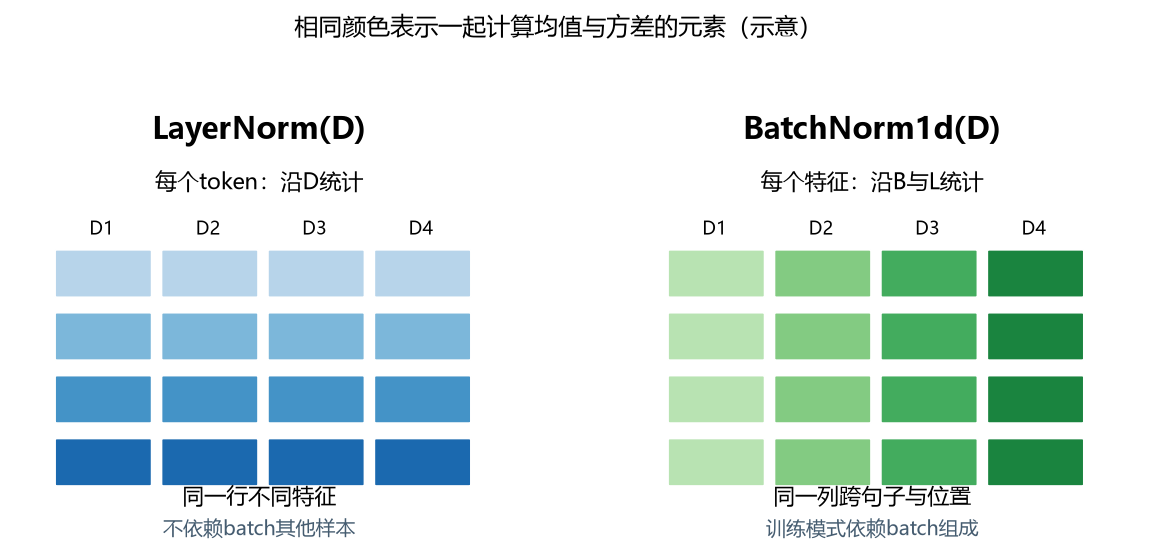

## 4. BN与LN、eval与no_grad：三组区别

| 问题 | LayerNorm(D) | BatchNorm1d(D)，输入转为 `(B,D,L)` |
| --- | --- | --- |
| 统计轴 | 每个token的D个特征 | 每个通道跨B和L |
| 更换batch里的其他句子 | 当前句子结果不受影响 | train模式下通常受影响 |
| 默认running统计量 | 没有 | 有running_mean/running_var |
| train/eval的统计来源 | 都取当前token | train取当前batch；eval默认取running统计 |
| 可训练仿射参数 | γ、β | γ、β |

`model.eval()`切换Dropout、默认BN等模块的行为，**不会冻结参数、不会关闭梯度**。`torch.no_grad()`停止记录自动求导图，**不会自动切换eval模式**。参数更新发生在optimizer.step；通常预测时同时使用eval和no_grad。

```python
anchor = torch.tensor([[[1., 2., 3., 4.], [2., 4., 6., 8.]]])
batch_a = torch.cat([anchor, anchor * 2], dim=0)
batch_b = torch.cat([anchor, anchor * 100 + 50], dim=0)
ln_axis = LayerNorm(4)
bn_axis = nn.BatchNorm1d(4, affine=False, track_running_stats=False)
with torch.no_grad():
    ln_a, ln_b = ln_axis(batch_a)[0], ln_axis(batch_b)[0]
    bn_a = bn_axis(batch_a.transpose(1, 2)).transpose(1, 2)[0]
    bn_b = bn_axis(batch_b.transpose(1, 2)).transpose(1, 2)[0]
torch.testing.assert_close(ln_a, ln_b)
assert not torch.allclose(bn_a, bn_b)
ln_axis.eval()
assert ln_axis(anchor).requires_grad  # eval仍可构建梯度图
with torch.no_grad():
    assert not ln_axis(anchor).requires_grad
assert all(p.requires_grad for p in ln_axis.parameters())
print('换batch同伴后的LN最大变化:', (ln_a - ln_b).abs().max().item())
print('换batch同伴后的BN最大变化:', round((bn_a - bn_b).abs().max().item(), 6))
print('eval不冻结参数，no_grad不修改requires_grad：通过')
```

本段实测输出：

```text
换batch同伴后的LN最大变化: 0.0
换batch同伴后的BN最大变化: 0.70785
eval不冻结参数，no_grad不修改requires_grad：通过
```

此处BN设置 `track_running_stats=False` 只为比较当前batch统计；在这种配置下eval也用当前batch统计，不能把它当作默认BN行为。

## 5. 残差子层与Pre-LN/Post-LN

课件第57、63、74页采用Pre-LN，并在编码器与解码器堆叠末尾增加LN：

$$\text{Pre-LN:}\quad y=x+\operatorname{Dropout}(\operatorname{Sublayer}(\operatorname{LN}(x)))$$
$$\text{Post-LN:}\quad y=\operatorname{LN}(x+\operatorname{Dropout}(\operatorname{Sublayer}(x)))$$

2017论文架构图画的是Post-LN，课程教学实现采用Pre-LN，两者操作顺序不同。本篇保持课程Pre-LN路线。不能把 `x+Dropout(LN(Sublayer(x)))` 叫作标准Post-LN，因为它没有对**残差相加的结果**做LN。

残差提供直接路径，但不保证任何深度、学习率都不会梯度爆炸。子层必须输出与x完全相同的shape；D→d_ff→D中的最后一步就是为此恢复维度。

```python
class SublayerConnection(nn.Module):
    def __init__(self, size, dropout=0.1):
        super().__init__()
        self.norm = LayerNorm(size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        branch = sublayer(self.norm(x))
        if branch.shape != x.shape:
            raise ValueError('残差两支必须具有相同shape')
        return x + self.dropout(branch)

residual = SublayerConnection(D, dropout=0.0)
x_res = torch.randn(2, 3, D, requires_grad=True)
y_res = residual(x_res, lambda z: z * 0)
torch.testing.assert_close(y_res, x_res)
y_res.sum().backward()
torch.testing.assert_close(x_res.grad, torch.ones_like(x_res))
print('子层输出0时保留输入，直接路径梯度为1：通过')
```

本段实测输出：

```text
子层输出0时保留输入，直接路径梯度为1：通过
```

`sublayer`是可调用对象。FFN只需一个输入，可直接传模块；MHA需要Q/K/V/mask，用 `lambda z: attention(z,z,z,mask)` 适配。z是**规范化后的输入**，若闭包误用外层原始x，会绕过LN。

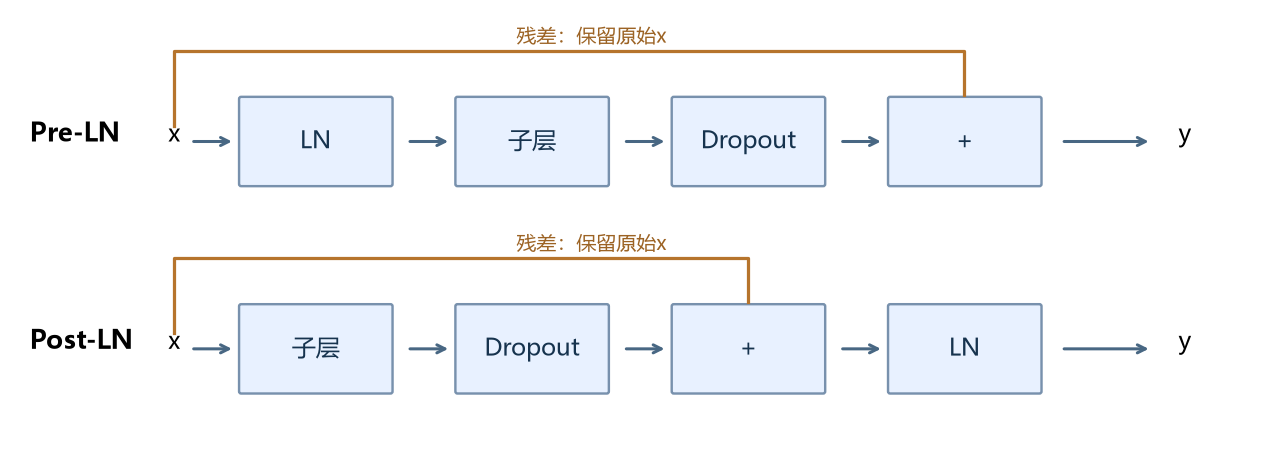

## 6. 复用08的基础组件：明确allow mask接口

下面集中列出Embedding、PE、MHA与FFN，保证本篇可以独立复制运行。详细推导见08。mask统一为**bool，True=允许参与注意力**，形状可广播到 `(B,H,Lq,Lk)`；这与部分官方API的布尔mask语义不同，调用时须转换。

MHA对全屏蔽query行直接报错，避免全 `-inf` 后softmax出现NaN。padding mask只屏蔽key列，不把PAD query整行屏蔽；PAD位置的输出由loss的ignore_index处理。

```python
class Embeddings(nn.Module):
    def __init__(self, d_model, vocab):
        super().__init__()
        self.lut = nn.Embedding(vocab, d_model, padding_idx=PAD)
        self.scale = math.sqrt(d_model)

    def forward(self, ids):
        return self.lut(ids) * self.scale

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=64):
        super().__init__()
        pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        freq = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * freq)
        pe[:, 1::2] = torch.cos(pos * freq[:pe[:, 1::2].shape[1]])
        self.register_buffer('pe', pe.unsqueeze(0))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        if x.size(1) > self.pe.size(1):
            raise ValueError('序列长度超过位置编码容量')
        return self.dropout(x + self.pe[:, :x.size(1)].to(dtype=x.dtype))

class MultiHeadAttention(nn.Module):
    def __init__(self, heads, d_model, dropout=0.1):
        super().__init__()
        if heads <= 0 or d_model % heads:
            raise ValueError('d_model必须能被正整数heads整除')
        self.heads, self.d_k = heads, d_model // heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.attn = None  # 只保存detach后的softmax权重供教学观察

    def forward(self, query, key, value, allow=None):
        if (query.ndim != 3 or key.ndim != 3 or value.ndim != 3
            or key.shape != value.shape or query.size(0) != key.size(0)
            or query.size(-1) != self.heads * self.d_k
            or key.size(-1) != query.size(-1)):
            raise ValueError('Q/K/V须为合法的(B,L,D)，K/V长度必须相同')
        b = query.size(0)
        def split(x, proj):
            return proj(x).reshape(b, -1, self.heads, self.d_k).transpose(1, 2)
        q, k, v = split(query, self.q_proj), split(key, self.k_proj), split(value, self.v_proj)
        scores = q @ k.transpose(-1, -2) / math.sqrt(self.d_k)
        if allow is not None:
            if allow.dtype != torch.bool:
                raise TypeError('allow必须是bool，True表示允许')
            mask = torch.broadcast_to(allow.to(scores.device), scores.shape)
            if not mask.any(dim=-1).all():
                raise ValueError('至少一个query没有可见key')
            scores = scores.masked_fill(~mask, float('-inf'))
        weights = scores.softmax(dim=-1)
        self.attn = weights.detach()
        context = self.dropout(weights) @ v
        context = context.transpose(1, 2).contiguous().view(b, query.size(1), -1)
        return self.out_proj(context)

class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.w2(self.dropout(F.relu(self.w1(x))))

def key_allow(ids):
    return (ids != PAD)[:, None, None, :]  # (B,1,1,Lk)

def target_allow(ids):
    length = ids.size(1)
    causal = torch.ones(length, length, dtype=torch.bool, device=ids.device).tril()
    return key_allow(ids) & causal[None, None, :, :]  # (B,1,T,T)

print('Embedding、PE、MHA、FFN与mask函数定义完成')
```

本段实测输出：

```text
Embedding、PE、MHA、FFN与mask函数定义完成
```

PE属于buffer，会随模型移动设备并进入state_dict，但不是优化器参数。`self.attn`只是最后一次前向的观察值；开启dropout时实际聚合使用的是dropout之后的权重，它的行和不必为1。教学版本保留权重便于检查，大规模训练可改为高效的官方注意力实现。

## 7. EncoderLayer：两个独立的残差子层

第一支MHA聚合源序列中不同位置，第二支FFN处理每个位置的特征。源端self-attention无需causal mask，但要屏蔽PAD key。这里Q/K/V输入同一组规范化特征，投影后的数值仍由各自权重决定。

```python
class EncoderLayer(nn.Module):
    def __init__(self, size, self_attn, feed_forward, dropout=0.1):
        super().__init__()
        self.size = size
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer = nn.ModuleList([SublayerConnection(size, dropout) for _ in range(2)])

    def forward(self, x, source_allow):
        x = self.sublayer[0](x, lambda z: self.self_attn(z, z, z, source_allow))
        return self.sublayer[1](x, self.feed_forward)

encoder_layer = EncoderLayer(D, MultiHeadAttention(H, D, 0.0),
                             PositionwiseFeedForward(D, 64, 0.0), 0.0).eval()
sample_src = torch.tensor([[4, 5, 6, EOS, PAD], [7, 8, EOS, PAD, PAD],
                           [6, 4, 8, 5, EOS]])
with torch.no_grad():
    one_layer_out = encoder_layer(torch.randn(B, 5, D), key_allow(sample_src))
assert one_layer_out.shape == (B, 5, D)
assert encoder_layer.self_attn.attn.shape == (B, H, 5, 5)
assert encoder_layer.sublayer[0].norm.gamma is not encoder_layer.sublayer[1].norm.gamma
print('EncoderLayer:', tuple(one_layer_out.shape))
print('两个子层的LN参数相互独立：通过')
```

本段实测输出：

```text
EncoderLayer: (3, 5, 32)
两个子层的LN参数相互独立：通过
```

## 8. clones、ModuleList与参数共享

课程用 `clones(layer,N)` 深拷贝层。`[layer]*N`会重复引用同一个对象，导致参数共享；`copy.deepcopy`得到独立存储，但初始数值可能完全相同。**独立参数不等于初始数值不同**。

```python
def clones(module, n):
    if n < 1:
        raise ValueError('层数至少为1')
    return nn.ModuleList([copy.deepcopy(module) for _ in range(n)])

prototype = nn.Linear(4, 4)
copies = clones(prototype, 2)
assert copies[0].weight.data_ptr() != copies[1].weight.data_ptr()
torch.testing.assert_close(copies[0].weight, copies[1].weight)
before_second = copies[1].weight.detach().clone()
with torch.no_grad():
    copies[0].weight.add_(1)
torch.testing.assert_close(copies[1].weight, before_second)
shared = nn.ModuleList([prototype] * 2)
assert shared[0].weight is shared[1].weight
print('deepcopy：初值相等但存储独立；重复引用：共享参数')
```

本段实测输出：

```text
deepcopy：初值相等但存储独立；重复引用：共享参数
```

ModuleList让层进入 `model.parameters()`、`state_dict()` 和 `.to(device)` 的递归管理，普通Python列表没有这种自动注册。下方完整模型工厂会**逐层重新构造**模块，直接得到独立初始化；两种路线都能实现N层堆叠。

## 9. Encoder：N层堆叠后得到memory

每层接收同一份源key mask，特征逐层更新；Pre-LN堆叠末尾再做最终LN。嵌入层位于整个Encoder之前，不是在每层重新把整数ID嵌入。

```python
class Encoder(nn.Module):
    def __init__(self, layers):
        super().__init__()
        if not layers:
            raise ValueError('Encoder至少需要一层')
        self.layers = nn.ModuleList(layers)
        self.norm = LayerNorm(layers[0].size)

    def forward(self, x, source_allow):
        for layer in self.layers:
            x = layer(x, source_allow)
        return self.norm(x)

encoder_test = Encoder(list(clones(encoder_layer, N))).eval()
with torch.no_grad():
    memory_test = encoder_test(torch.randn(B, 5, D), key_allow(sample_src))
assert memory_test.shape == (B, 5, D)
assert encoder_test.layers[0].self_attn.q_proj.weight is not encoder_test.layers[1].self_attn.q_proj.weight
print('Encoder memory:', tuple(memory_test.shape), '| 层数:', len(encoder_test.layers))
```

本段实测输出：

```text
Encoder memory: (3, 5, 32) | 层数: 2
```

PAD query位置仍可能有非零特征，因位置编码、偏置、残差和对有效key的注意力都可产生数值。关键是每一层都屏蔽PAD key，解码器cross-attention也屏蔽对应memory列，不能仅依赖padding_idx让embedding为0。

## 10. DecoderLayer：三种注意力的分工

| 注意力 | Q输入 | K/V输入 | 权重形状 | mask用途 |
| --- | --- | --- | --- | --- |
| Encoder self-attention | 源端当前特征 | 源端当前特征 | `(B,H,S,S)` | 源PAD key |
| Decoder self-attention | 目标端当前特征 | 目标端当前特征 | `(B,H,T,T)` | 目标PAD key + 未来key |
| Decoder cross-attention | 目标端当前特征 | memory | `(B,H,T,S)` | 源PAD key |

cross-attention输出长度是T，残差也加在目标端x上。每一层解码器读取同一份最终memory，但有自己的Q/K/V投影，因此各层注意力分布可以不同。memory在一次解码调用中不会被各层改写；训练时梯度仍会经cross-attention回传Encoder。

```python
class DecoderLayer(nn.Module):
    def __init__(self, size, self_attn, src_attn, feed_forward, dropout=0.1):
        super().__init__()
        self.size = size
        self.self_attn = self_attn
        self.src_attn = src_attn
        self.feed_forward = feed_forward
        self.sublayer = nn.ModuleList([SublayerConnection(size, dropout) for _ in range(3)])

    def forward(self, x, memory, source_allow, target_allow_mask):
        x = self.sublayer[0](x, lambda z: self.self_attn(z, z, z, target_allow_mask))
        x = self.sublayer[1](x, lambda z: self.src_attn(z, memory, memory, source_allow))
        return self.sublayer[2](x, self.feed_forward)

decoder_layer = DecoderLayer(D, MultiHeadAttention(H, D, 0.0),
    MultiHeadAttention(H, D, 0.0), PositionwiseFeedForward(D, 64, 0.0), 0.0).eval()
sample_tgt = torch.tensor([[BOS, 4, 5, 6, EOS, PAD],
                           [BOS, 7, 8, EOS, PAD, PAD],
                           [BOS, 6, 4, 8, 5, EOS]])
with torch.no_grad():
    decoded_test = decoder_layer(torch.randn(B, 6, D), memory_test,
                                 key_allow(sample_src), target_allow(sample_tgt))
assert decoded_test.shape == (B, 6, D)
assert decoder_layer.self_attn.attn.shape == (B, H, 6, 6)
assert decoder_layer.src_attn.attn.shape == (B, H, 6, 5)
assert decoder_layer.self_attn.q_proj.weight is not decoder_layer.src_attn.q_proj.weight
print('DecoderLayer:', tuple(decoded_test.shape))
print('self/cross权重:', tuple(decoder_layer.self_attn.attn.shape), tuple(decoder_layer.src_attn.attn.shape))
```

本段实测输出：

```text
DecoderLayer: (3, 6, 32)
self/cross权重: (3, 4, 6, 6) (3, 4, 6, 5)
```

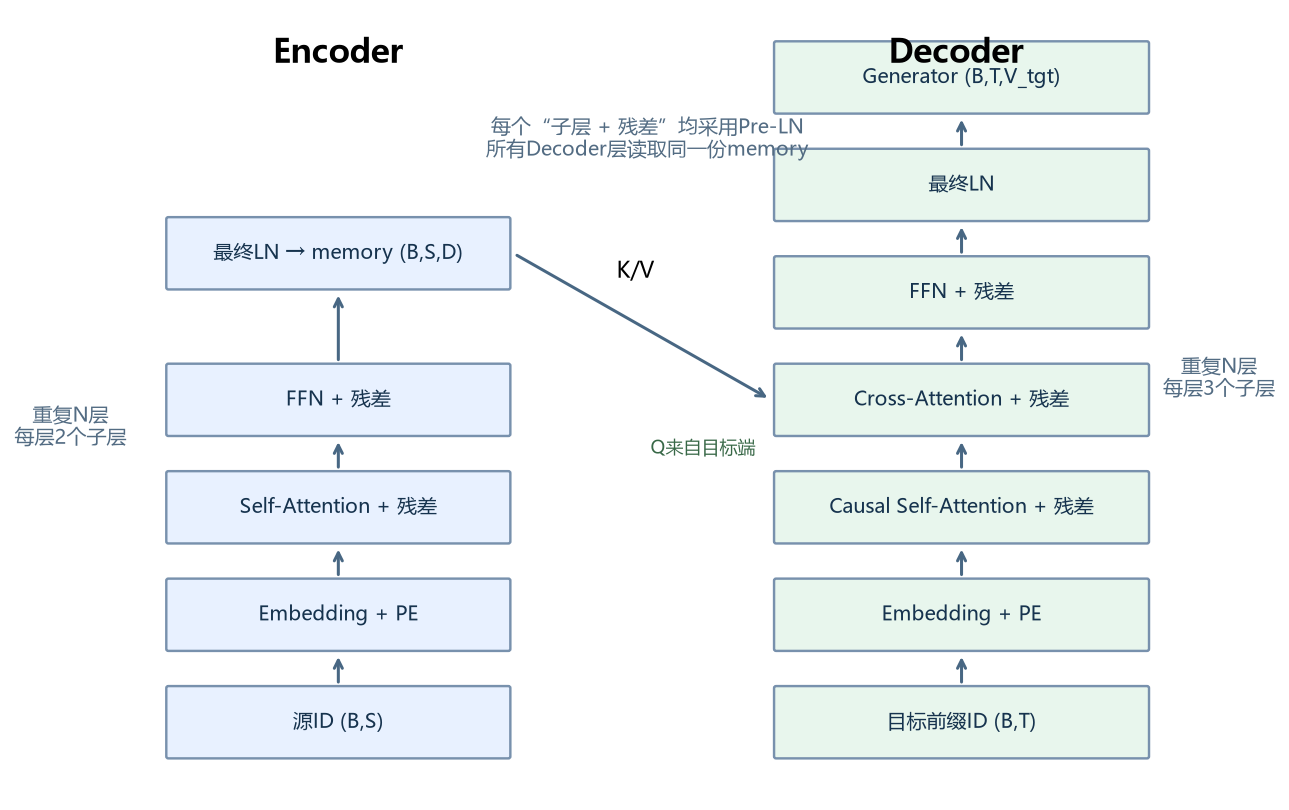

## 11. Decoder：堆叠时保持memory不变

```python
class Decoder(nn.Module):
    def __init__(self, layers):
        super().__init__()
        if not layers:
            raise ValueError('Decoder至少需要一层')
        self.layers = nn.ModuleList(layers)
        self.norm = LayerNorm(layers[0].size)

    def forward(self, x, memory, source_allow, target_allow_mask):
        for layer in self.layers:
            x = layer(x, memory, source_allow, target_allow_mask)
        return self.norm(x)

decoder_test = Decoder(list(clones(decoder_layer, N))).eval()
saved_memory = memory_test.clone()
with torch.no_grad():
    decoder_out = decoder_test(torch.randn(B, 6, D), memory_test,
                              key_allow(sample_src), target_allow(sample_tgt))
torch.testing.assert_close(memory_test, saved_memory)
print('Decoder:', tuple(decoder_out.shape), '| memory未被改写：通过')
```

本段实测输出：

```text
Decoder: (3, 6, 32) | memory未被改写：通过
```

Decoder输出是目标位置的隐藏特征，还不是词表概率，更不是已经完成的句子。Generator、选词、EOS终止和生成循环属于后续步骤。

## 12. Generator：logits、概率与对数概率

线性层把D映射到**目标词表大小V_tgt**。例如D=512、V_tgt=1000时，softmax沿1000维，不是512维；课件第83页的512示例需结合线性层输出重新理解。

$$z=xW+b,\qquad \log p_i=z_i-\log\sum_j e^{z_j}$$

| 输出 | 含义 | 常见损失搭配 |
| --- | --- | --- |
| logits z | 未归一化分数，可正可负 | CrossEntropyLoss |
| softmax(z) | 概率，沿词表求和为1 | 通常不直接传给CE |
| log_softmax(z) | 对数概率，exp后沿词表求和为1 | NLLLoss |

```python
class Generator(nn.Module):
    def __init__(self, d_model, vocab_size):
        super().__init__()
        self.project = nn.Linear(d_model, vocab_size)

    def logits(self, x):
        return self.project(x)

    def forward(self, x):
        return F.log_softmax(self.logits(x), dim=-1)

gen_test = Generator(D, 12)
hidden_test = torch.randn(B, 6, D)
logits_test = gen_test.logits(hidden_test)
log_probs_test = gen_test(hidden_test)
torch.testing.assert_close(log_probs_test.exp().sum(-1), torch.ones(B, 6))
labels_test = torch.randint(1, 12, (B, 6))
ce = F.cross_entropy(logits_test.reshape(-1, 12), labels_test.reshape(-1))
nll = F.nll_loss(log_probs_test.reshape(-1, 12), labels_test.reshape(-1))
torch.testing.assert_close(ce, nll)
print('Generator:', tuple(log_probs_test.shape))
print('CE(logits)与NLL(log_probs)差值:', (ce - nll).abs().item())
```

本段实测输出：

```text
Generator: (3, 6, 12)
CE(logits)与NLL(log_probs)差值: 0.0
```

对数概率的各项求和不等于1，可能都是负数。不要先softmax再交给CrossEntropyLoss；若接口明确返回log_probs，就用NLLLoss。本篇EncoderDecoder.forward保持课件习惯，返回log_probs。

## 13. EncoderDecoder与make_model：统一组装入口

`encode`返回memory；`decode`返回目标隐藏特征；`forward`完成编码、解码、Generator，返回log_probs。分开encode/decode方便生成时只计算一次源端memory。

```python
class EncoderDecoder(nn.Module):
    def __init__(self, encoder, decoder, source_embed, target_embed, generator):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder
        self.source_embed, self.target_embed = source_embed, target_embed
        self.generator = generator

    def encode(self, source, source_allow):
        return self.encoder(self.source_embed(source), source_allow)

    def decode(self, memory, source_allow, target, target_allow_mask):
        return self.decoder(self.target_embed(target), memory, source_allow, target_allow_mask)

    def forward(self, source, target, source_allow, target_allow_mask):
        memory = self.encode(source, source_allow)
        hidden = self.decode(memory, source_allow, target, target_allow_mask)
        return self.generator(hidden)

def make_model(source_vocab, target_vocab, n=2, d_model=32, d_ff=64,
               heads=4, dropout=0.1, max_len=64):
    if n < 1 or source_vocab <= EOS or target_vocab <= EOS:
        raise ValueError('层数或词表大小不合法')
    def attn():
        return MultiHeadAttention(heads, d_model, dropout)
    def ff():
        return PositionwiseFeedForward(d_model, d_ff, dropout)
    encoder_layers = [EncoderLayer(d_model, attn(), ff(), dropout) for _ in range(n)]
    decoder_layers = [DecoderLayer(d_model, attn(), attn(), ff(), dropout) for _ in range(n)]
    model = EncoderDecoder(Encoder(encoder_layers), Decoder(decoder_layers),
        nn.Sequential(Embeddings(d_model, source_vocab), PositionalEncoding(d_model, dropout, max_len)),
        nn.Sequential(Embeddings(d_model, target_vocab), PositionalEncoding(d_model, dropout, max_len)),
        Generator(d_model, target_vocab))
    # 教学扩展：对二维权重做Xavier初始化，LN的一维参数保留默认值。
    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    # 通用初始化覆盖了Embedding的PAD行，显式恢复为0。
    with torch.no_grad():
        model.source_embed[0].lut.weight[PAD].zero_()
        model.target_embed[0].lut.weight[PAD].zero_()
    return model

torch.manual_seed(2026)
model = make_model(16, 12, n=N, d_model=D, d_ff=64, heads=H, dropout=0.0)
param_count = sum(p.numel() for p in model.parameters())
assert model.source_embed[0].lut.weight.shape == (16, D)
assert model.target_embed[0].lut.weight.shape == (12, D)
assert model.decoder.layers[0].self_attn.q_proj.weight is not model.decoder.layers[0].src_attn.q_proj.weight
assert model.encoder.layers[0].self_attn.q_proj.weight is not model.encoder.layers[1].self_attn.q_proj.weight
assert not torch.equal(model.encoder.layers[0].self_attn.q_proj.weight,
                       model.encoder.layers[1].self_attn.q_proj.weight)
print('总参数量:', param_count)
print('源/目标词表独立，层之间及self/cross参数独立：通过')
```

本段实测输出：

```text
总参数量: 44172
源/目标词表独立，层之间及self/cross参数独立：通过
```

本篇逐层创建attention/FFN，课程用deepcopy原型，接口含义相同。源端与目标端分别创建Embedding；即使词表大小相同，也不能默认它们是同一词表。词表相同并显式设计时才考虑参数绑定。

课件第94页说“新建Embedding后不可以深拷贝”过于绝对。`deepcopy(Embeddings(...))`在技术上可行，只是刚创建的独立模块再复制没有必要；编码端Embedding只在整个Encoder之前调用一次，各EncoderLayer实际接收浮点特征，均不直接调用Embedding。

## 14. 目标右移与三种mask：防止答案泄漏

假设目标是 `4 5 6 EOS`：

| 输入位置 | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| decoder输入 | BOS | 4 | 5 | 6 | EOS |
| 监督标签 | 4 | 5 | 6 | EOS | PAD，忽略 |

causal mask允许对角线：当前输入token已经是**前一个监督token**，并没有看到当前位置的目标答案。课件“屏蔽当前”说的是待预测的当前目标词，而不是把右移后的输入对角线也屏蔽。严格屏蔽对角线会让BOS行没有可见key。

```python
source = sample_src.clone()  # (3,5)
target_full = torch.tensor([[BOS, 4, 5, 6, EOS, PAD, PAD],
                            [BOS, 7, 8, EOS, PAD, PAD, PAD],
                            [BOS, 6, 4, 8, 5, EOS, PAD]])
target_input = target_full[:, :-1]  # (3,6)
target_label = target_full[:, 1:]   # (3,6)，与输入错一位
source_mask = key_allow(source)    # (3,1,1,5)，self/cross均可广播
target_mask = target_allow(target_input)  # (3,1,6,6)
assert source_mask.shape == (B, 1, 1, 5)
assert target_mask.shape == (B, 1, 6, 6)
assert target_mask.any(-1).all()  # PAD query仍有有效前缀可见
valid_tokens = (target_label != PAD).sum().item()
print('源输入:', tuple(source.shape), '| 目标输入/标签:', tuple(target_input.shape))
print('源mask:', tuple(source_mask.shape), '| 目标mask:', tuple(target_mask.shape))
print('有效监督token数:', valid_tokens)
```

本段实测输出：

```text
源输入: (3, 5) | 目标输入/标签: (3, 6)
源mask: (3, 1, 1, 5) | 目标mask: (3, 1, 6, 6)
有效监督token数: 12
```

Encoder源self-attention的scores是 `(B,H,S,S)`；Decoder cross-attention是 `(B,H,T,S)`。同一个 `(B,1,1,S)` 源mask可用于两处，是因为它只描述源key列。目标mask则必须同时表达T个query与T个key的因果关系。

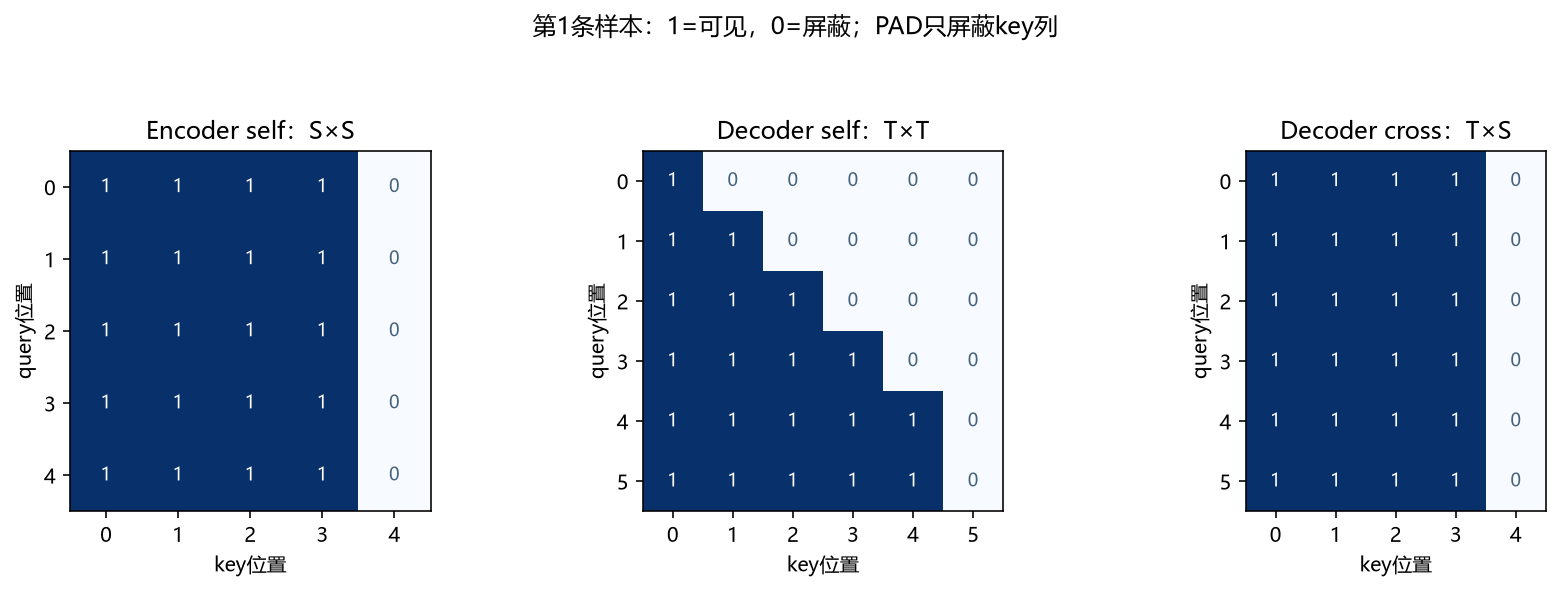

## 15. 完整前向：逐段观察shape与概率

用forward hook观察模块边界，验收后移除hook，避免重复运行时累积记录。完整Transformer返回词表分布，而encode/decode接口分别返回memory与隐藏特征。

```python
model.eval()
shape_trace, handles = [], []
def shape_hook(name):
    def record(module, args, output):
        shape_trace.append((name, tuple(output.shape)))
    return record
for name in ['source_embed', 'encoder', 'target_embed', 'decoder', 'generator']:
    handles.append(getattr(model, name).register_forward_hook(shape_hook(name)))
try:
    with torch.no_grad():
        log_probs = model(source, target_input, source_mask, target_mask)
finally:
    for handle in handles:
        handle.remove()
assert log_probs.shape == (B, 6, 12)
assert torch.isfinite(log_probs).all()
torch.testing.assert_close(log_probs.exp().sum(-1), torch.ones(B, 6), atol=1e-6, rtol=1e-6)
for name, shape in shape_trace:
    print(name, '→', shape)
print('有限输出、每个位置概率和为1：通过')
```

本段实测输出：

```text
source_embed → (3, 5, 32)
encoder → (3, 5, 32)
target_embed → (3, 6, 32)
decoder → (3, 6, 32)
generator → (3, 6, 12)
有限输出、每个位置概率和为1：通过
```

训练阶段，给定右移的真实目标前缀，可以在一遍前向中并行算出T个位置的监督分布；推理时未来token未知，需要逐步生成。因此“Transformer解码一定按时间步计算”只适用于自回归生成，不能用来描述teacher forcing训练的实现。

## 16. 不能只看shape：未来与PAD扰动检查

此处关闭dropout并使用eval，才能把变化归因于掩码。检查三件事：改变未来输入不影响早期log_probs；改变源PAD处特征不影响有效源编码与cross输出；改变目标PAD处特征不影响有效目标位置。

```python
with torch.no_grad():
    # 1. 把位置3及之后的目标输入换掉，早期位置0..2必须不变。
    future_changed = target_input.clone()
    future_changed[:, 3:] = 9
    future_out = model(source, future_changed, source_mask, target_mask)
    future_error = (log_probs[:, :3] - future_out[:, :3]).abs().max().item()
    torch.testing.assert_close(log_probs[:, :3], future_out[:, :3], atol=2e-6, rtol=2e-6)

    # 2. 在源PAD位置加大扰动，mask仍由原source决定。
    src_emb = model.source_embed(source)
    src_changed = src_emb + (source == PAD).unsqueeze(-1) * torch.randn_like(src_emb) * 100
    mem_a = model.encoder(src_emb, source_mask)
    mem_b = model.encoder(src_changed, source_mask)
    src_pad_error = (mem_a[source != PAD] - mem_b[source != PAD]).abs().max().item()
    torch.testing.assert_close(mem_a[source != PAD], mem_b[source != PAD], atol=2e-6, rtol=2e-6)
    dec_a = model.decode(mem_a, source_mask, target_input, target_mask)
    dec_b = model.decode(mem_b, source_mask, target_input, target_mask)
    torch.testing.assert_close(dec_a, dec_b, atol=2e-6, rtol=2e-6)

    # 3. 目标PAD位置同样可有数值，但不能影响其他有效query。
    tgt_emb = model.target_embed(target_input)
    tgt_changed = tgt_emb + (target_input == PAD).unsqueeze(-1) * torch.randn_like(tgt_emb) * 100
    hid_a = model.decoder(tgt_emb, mem_a, source_mask, target_mask)
    hid_b = model.decoder(tgt_changed, mem_a, source_mask, target_mask)
    torch.testing.assert_close(hid_a[target_input != PAD], hid_b[target_input != PAD], atol=2e-6, rtol=2e-6)

    for layer in model.encoder.layers:
        blocked = (~source_mask).expand_as(layer.self_attn.attn)
        assert (layer.self_attn.attn[blocked] == 0).all()
    for layer in model.decoder.layers:
        assert (layer.self_attn.attn[(~target_mask).expand_as(layer.self_attn.attn)] == 0).all()
        assert (layer.src_attn.attn[(~source_mask).expand_as(layer.src_attn.attn)] == 0).all()
print('未来扰动最大误差:', future_error)
print('源PAD扰动后有效memory最大误差:', src_pad_error)
print('源/目标PAD隔离、全部层屏蔽权重为0：通过')
```

本段实测输出：

```text
未来扰动最大误差: 0.0
源PAD扰动后有效memory最大误差: 0.0
源/目标PAD隔离、全部层屏蔽权重为0：通过
```

mask仍由原始有效长度构建，不能在“扰动PAD”的同时把PAD改成有效token并重建mask，那是在改变输入语义。测试必须覆盖所有层；某一层漏传mask，后面的层可能已通过PAD传播错误信息。

## 17. Loss与反向传播：PAD不参与监督

把 `(B,T,V_tgt)` 展为 `(B*T,V_tgt)`，标签展为 `(B*T)`。`NLLLoss(ignore_index=PAD)`的mean按有效标签计数，本例共12个监督token。EOS是有效标签，PAD才被忽略。

```python
model.train()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
optimizer.zero_grad(set_to_none=True)
train_log_probs = model(source, target_input, source_mask, target_mask)
loss = F.nll_loss(train_log_probs.reshape(-1, 12), target_label.reshape(-1), ignore_index=PAD)
picked = train_log_probs.gather(-1, target_label.unsqueeze(-1)).squeeze(-1)
manual_loss = -picked[target_label != PAD].mean()
torch.testing.assert_close(loss, manual_loss)
loss.backward()
groups = {'source_embed': model.source_embed, 'encoder': model.encoder,
          'target_embed': model.target_embed, 'decoder': model.decoder,
          'generator': model.generator}
grad_norms = {}
for name, module in groups.items():
    grads = [p.grad for p in module.parameters() if p.requires_grad]
    assert all(g is not None and torch.isfinite(g).all() for g in grads)
    grad_norms[name] = math.sqrt(sum(g.square().sum().item() for g in grads))
    assert grad_norms[name] > 0
assert model.source_embed[0].lut.weight.grad[PAD].abs().sum() == 0
assert model.target_embed[0].lut.weight.grad[PAD].abs().sum() == 0
old_weight = model.generator.project.weight.detach().clone()
total_grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()
assert not torch.equal(old_weight, model.generator.project.weight)
first_loss = loss.item()
print('单批loss:', round(first_loss, 6), '| 有效标签:', valid_tokens)
print('各组件梯度范数:', {k: round(v, 6) for k,v in grad_norms.items()})
print('PAD embedding梯度为0、一次参数更新：通过')
```

本段实测输出：

```text
单批loss: 3.464263 | 有效标签: 12
各组件梯度范数: {'source_embed': 0.847524, 'encoder': 1.520159, 'target_embed': 1.230515, 'decoder': 3.176332, 'generator': 1.921029}
PAD embedding梯度为0、一次参数更新：通过
```

这证明计算图已贯通到源Embedding与Encoder，不能据此声称模型已学会翻译。mask负责阻止注意力读取PAD，ignore_index负责让PAD标签不贡献loss，两者各自解决不同问题。这里用Adam且无weight decay；PAD行不会因本例更新产生变化。

## 18. 教学扩展：固定小批次复制任务

day09的主线是架构实现。下面额外让模型记住三条人工序列，检查loss是否下降，帮助区分“搭好计算图”和“优化能进行”。源目标整数在这个复制任务中约定同义，但两端Embedding和词表大小仍不同。

只在同一批数据上训练与验收，没有验证集；即使复制完全正确，也只能说明这三条样本被拟合。正式任务还需语料划分、词表/分词器、学习率调度、checkpoint、验证指标等。

```python
loss_history = [first_loss]
for step in range(1, 201):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    prediction = model(source, target_input, source_mask, target_mask)
    current_loss = F.nll_loss(prediction.reshape(-1, 12), target_label.reshape(-1), ignore_index=PAD)
    current_loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    loss_history.append(current_loss.item())
    if current_loss.item() < 0.01:
        break
model.eval()
with torch.no_grad():
    fitted_log_probs = model(source, target_input, source_mask, target_mask)
    fitted_loss = F.nll_loss(fitted_log_probs.reshape(-1, 12), target_label.reshape(-1), ignore_index=PAD).item()
    fitted_ids = fitted_log_probs.argmax(-1)
    train_token_accuracy = (fitted_ids[target_label != PAD] == target_label[target_label != PAD]).float().mean().item()
assert fitted_loss < first_loss * 0.1
assert train_token_accuracy == 1.0
print('额外更新步数:', step)
print('训练批loss:', round(first_loss, 6), '→', round(fitted_loss, 6))
print('同批teacher forcing有效token准确率:', train_token_accuracy)
plt.figure(figsize=(7.5, 3.4))
plt.plot(loss_history, color='#2874b6', lw=2)
plt.xlabel('更新前loss的记录序号'); plt.ylabel('有效token平均NLL')
plt.title('三条固定训练样本的拟合曲线（不是验证集表现）')
plt.grid(alpha=0.2); plt.tight_layout(); plt.show()
```

本段实测输出：

```text
额外更新步数: 14
训练批loss: 3.464263 → 0.008091
同批teacher forcing有效token准确率: 1.0
```

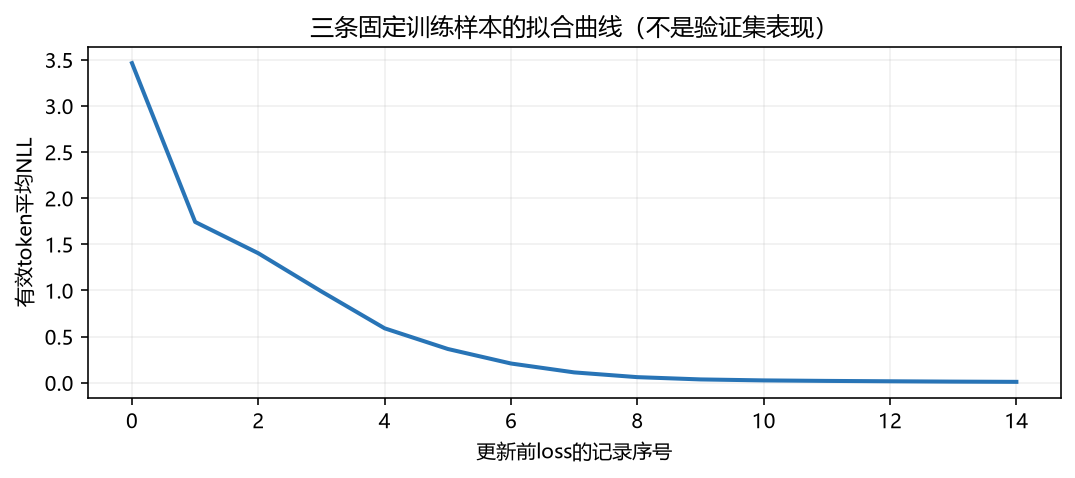

## 19. 贪心生成：只计算一次memory

生成从BOS开始，每轮用当前完整前缀重新解码，取最后一个位置的词表分布并选择argmax，遇EOS后停止对应样本。已结束的样本追加PAD，尚未结束的继续生成。最大生成长度防止未生成EOS时无限循环。

本篇为简化接口不实现KV cache，目标前缀每轮重算；源memory只编码一次。eval关闭dropout，no_grad避免保存梯度图。这里只禁止生成PAD和BOS，不加入任何参考答案。

```python
@torch.no_grad()
def greedy_decode(model, source, max_new_tokens=8):
    if max_new_tokens < 1 or max_new_tokens > model.target_embed[1].pe.size(1):
        raise ValueError('生成步数超出位置编码可用范围')
    was_training = model.training
    model.eval()
    try:
        src_mask = key_allow(source)
        memory = model.encode(source, src_mask)
        ys = torch.full((source.size(0), 1), BOS, dtype=torch.long, device=source.device)
        finished = torch.zeros(source.size(0), dtype=torch.bool, device=source.device)
        for _ in range(max_new_tokens):
            hidden = model.decode(memory, src_mask, ys, target_allow(ys))
            last = model.generator(hidden[:, -1]).clone()
            last[:, PAD] = float('-inf')
            last[:, BOS] = float('-inf')
            next_id = last.argmax(dim=-1)
            next_id = torch.where(finished, torch.full_like(next_id, PAD), next_id)
            ys = torch.cat([ys, next_id[:, None]], dim=1)
            finished |= next_id.eq(EOS)
            if finished.all():
                break
        return ys
    finally:
        model.train(was_training)

generated = greedy_decode(model, source)
def content_until_eos(row):
    values = row.tolist()
    if EOS not in values:
        raise AssertionError('本批样本未生成EOS')
    return values[:values.index(EOS) + 1]
for i in range(B):
    got = content_until_eos(generated[i, 1:])
    expected = content_until_eos(target_label[i])
    assert got == expected
    print('样本', i + 1, '生成:', got, '| 目标:', expected)
print('自回归生成匹配3条训练样本，EOS终止：通过')
```

本段实测输出：

```text
样本 1 生成: [4, 5, 6, 2] | 目标: [4, 5, 6, 2]
样本 2 生成: [7, 8, 2] | 目标: [7, 8, 2]
样本 3 生成: [6, 4, 8, 5, 2] | 目标: [6, 4, 8, 5, 2]
自回归生成匹配3条训练样本，EOS终止：通过
```

teacher forcing准确率是给定真实前缀下的结果，贪心生成则使用自己的历史预测；两者可能不同。本例额外检查生成序列，仍属于训练样本上的验收。贪心也不保证找到全序列概率最大的句子。

## 20. 课件核对与常见错误

| 位置或现象 | 容易误读的点 | 本篇处理 |
| --- | --- | --- |
| 第52、54—55页 | LN“学习所有batch均值方差”，eval“冻结a2/b2” | LN每次沿当前token特征计算统计，γ/β可学习；eval不冻结参数 |
| 第52页 | `std`与官方LN完全相同 | correction=0总体方差，eps加在方差内；已与官方LN对照 |
| 第57页 | 三种写法可视为同一种结构 | 区分Pre-LN、Post-LN与仅规范化分支的第三种结构 |
| 第58、61、70、75、88、91页 | 测试用全0mask就证明注意力正常 | 本篇True=允许，拒绝全屏蔽行，用非平凡PAD和causal mask验收 |
| 第70页 | `self_attn=src_attn=同一对象` | 该写法共享参数；完整模型为两者分别创建模块 |
| 第71—72页 | 解码只能顺序计算、必须屏蔽输入对角线 | 训练可并行；右移输入允许对角线，生成才逐步进行 |
| 第83页 | softmax在原D维上 | 线性层后在V_tgt维上，log_softmax输出对数概率 |
| 第94页 | 新建Embedding“不能深拷贝” | 技术上能复制，只是无必要；Embedding在层堆叠前调用一次 |
| Decoder cross输出长度等于S | 把memory长度当成query长度 | cross权重T×S，输出长度为T |
| 把PAD query整行mask为False | 认为能让PAD输出自动为0 | 容易全屏蔽产生NaN；屏蔽key列并忽略PAD标签 |
| 只在最外层传mask | 内部某层遗漏 | 所有Encoder层、Decoder self/cross逐层传递并检查权重 |
| 把`[layer]*N`当作克隆 | 多层看似存在但实际共享 | 深拷贝或逐层新建，并检查参数对象/存储 |

这些说明针对已阅读的PDF，不推断课程视频或原代码是否另有修正。课程教学示例主要演示接口，真实批次还应明确长度、词表ID、device和数据类型。迁移学习、预训练模型与BERT留待后续天数。

## 21. 复习题与参考答案

1. **`(B,T,D)`的LN统计轴是什么？** 最后一维D；每个token单独计算，不混合B/T。
2. **为什么每个残差子层都有自己的LN？** 各子层输入分布和功能不同，应有独立γ/β；不能无意共享同一个模块。
3. **Pre-LN堆叠为什么最后还加LN？** 每层残差相加后未做LN，课程在堆叠输出再规范化，给下一模块提供规范化特征。
4. **每层Decoder都用同一memory，是否共享cross-attention参数？** 不共享；输入memory相同，各层可有独立投影。
5. **S=5、T=6时cross权重和输出shape？** `(B,H,6,5)`与`(B,6,D)`。
6. **词表大小不同，source与target可用同一个Embedding吗？** 本例不能。即使大小相同也要核对token ID语义；只有明确设计的共享词表才适合绑定。
7. **`ignore_index=PAD`能替代注意力mask吗？** 不能。忽略标签只影响loss，模型仍可能通过注意力读取PAD。
8. **为什么target_input和target_label右移一位？** 当前输入表示已知前缀，当前输出监督下一个token，配合causal mask防止直接读取答案。
9. **`model.eval()`后还能backward吗？** 可以，只要未处于no_grad且参与计算的参数需要梯度；eval只切换模块行为。
10. **log_probs各项求和为什么不是1？** 它是log(p)，exp后才得到概率。
11. **deepcopy初值相同是否等于参数共享？** 不等于；看参数对象和存储，更新某层是否影响另一层。
12. **训练批复制成功说明什么？** 实现能前向、反向、优化和自回归生成，并拟合这些样本；不能代表未见数据的泛化与翻译质量。

建议练习：把源句长度改为7、目标输入长度改为4，先画出三个scores与mask的形状，再修改数据和assert；保持B≠H，确认cross-attention不依赖S=T。另一项练习是在某个Decoder层故意漏传target mask，观察未来扰动检查如何失败。

## 22. day09资料索引与实测范围

来源：[NLP自然语言处理网盘资料](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。课程文件夹 `2026最新版NLP自然语言处理`；课件 `01-课件/08-Tranformer架构和实现.pdf`，本篇阅读第51—95页；视频 `03-视频/day09`，共18个文件。

| 视频 | 原文件主题 | 本篇对应 |
| --- | --- | --- |
| 01 | 规范化层_代码实现(掌握) | 第3节 |
| 02 | 规范化层_代码测试(理解) | 第3节 |
| 03 | 扩展_BN和LN的区别(理解) | 第4节 |
| 04 | 子层结构搭建_代码实现(掌握) | 第5节 |
| 05 | 子层结构搭建_代码测试(理解) | 第5节 |
| 06 | 编码器层_代码实现(掌握) | 第7节 |
| 07 | 编码器层_代码测试(理解) | 第7节 |
| 08 | 编码器_代码实现及测试(掌握) | 第8—9节 |
| 09 | 解码器层_代码实现(掌握) | 第10节 |
| 10 | 解码器层_代码测试(理解) | 第10节 |
| 11 | 解码器_代码实现及测试(掌握) | 第11节 |
| 12 | 输出部分_代码实现(掌握) | 第12节 |
| 13 | 输出部分_代码测试(理解) | 第12节 |
| 14 | 完整的Transformer架构搭建_上(掌握) | 第13节 |
| 15 | 完整的Transformer架构搭建_下(掌握) | 第13节 |
| 16 | Transformer架构测试_上(理解) | 第14—16节 |
| 17 | Transformer架构组件介绍(理解) | 第1、13节 |
| 18 | Transformer架构测试_下(理解) | 第15—16节 |

本篇示例是独立教学实现，未使用课程原代码和原数据集。官方LN数值对照、BN/LN批次扰动、残差直接路径、参数独立性、非等长cross-attention、全层mask隔离、有效标签loss、梯度与更新、固定小批次复制及贪心生成均已实际执行。第16—19节为补充验收，不声称是视频逐字内容或完整翻译训练工程。

图片均为本篇制作的示意图或代码实际绘图，嵌入本Notebook内部；图中的Pre-LN路线与实现一致。